In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression

In [3]:
df = pd.read_csv("h.csv")

In [4]:
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,yes,no,yes,no,no,2.0,no,unfurnished
541,1767150,2400,3.0,1.0,1.0,no,no,no,no,no,0.0,no,semi-furnished
542,1750000,3620,2.0,1.0,1.0,yes,no,no,no,no,0.0,no,unfurnished
543,1750000,2910,3.0,1.0,1.0,no,no,no,no,no,0.0,no,furnished


In [5]:
df = df.drop_duplicates()

In [6]:
df.isnull().sum()

price               0
area                0
bedrooms            5
bathrooms           5
stories             2
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             4
prefarea            0
furnishingstatus    0
dtype: int64

In [7]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished


In [8]:
df["bedrooms"] = df["bedrooms"].fillna(df["bedrooms"].median())
df["bathrooms"] = df["bathrooms"].fillna(df["bathrooms"].median())
df["stories"] = df["stories"].fillna(df["stories"].median())
df["parking"] = df["parking"].fillna(df["parking"].median())

In [9]:
le = LabelEncoder()

In [10]:
df["mainroad"] = le.fit_transform(df["mainroad"])
df["guestroom"] = le.fit_transform(df["guestroom"])
df["basement"] = le.fit_transform(df["basement"])
df["hotwaterheating"] = le.fit_transform(df["hotwaterheating"])
df["airconditioning"] = le.fit_transform(df["airconditioning"])
df["parking"] = le.fit_transform(df["parking"])
df["prefarea"] = le.fit_transform(df["prefarea"])


In [11]:
df["furnishingstatus"] = df["furnishingstatus"].map({
    "furnished": 3,
    "semi-furnished": 2,
    "unfurnished": 1 })

In [12]:
df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,1,0,0,0,1,2,1,3
1,12250000,8960,4.0,4.0,4.0,1,0,0,0,1,3,0,3
2,12250000,9960,3.0,2.0,2.0,1,0,1,0,0,2,1,2
3,12215000,7500,4.0,2.0,2.0,1,0,1,0,1,3,1,3
4,11410000,7420,4.0,1.0,2.0,1,1,1,0,1,2,0,3


In [13]:
X = df[["area"]]
y = df["price"]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=46)

In [15]:
reg = LinearRegression()
reg.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [16]:
print("Coef:", reg.coef_)
print("Intercept", reg.intercept_)

Coef: [475.79332031]
Intercept 2339304.347835016


In [17]:
y_pred = reg.predict(X_test)
y_pred1 = reg.predict(X_train) 

In [18]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r_square = r2_score(y_test, y_pred)

In [19]:
print(mse)
print(mae)
print(r_square)

2133125175144.4172
1156124.9411081714
0.2817763154271622


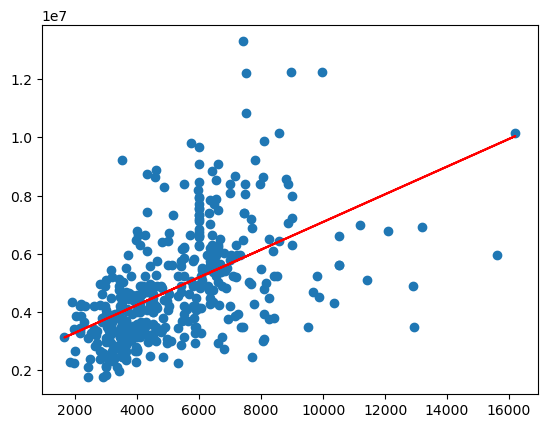

In [20]:
plt.scatter(X_train ,y_train)
plt.plot(X_train, y_pred1, c="Red")
plt.show()

In [21]:
X1= df.drop("price", axis = 1)
y1 = df["price"]

In [22]:
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.2, random_state=46)

In [23]:
regg = LinearRegression()

In [24]:
df.isnull().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [25]:
df["price"] = pd.to_numeric(df["price"], errors="coerce")

In [26]:
regg.fit(X1_train, y1_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [27]:
print("Coef", regg.coef_)
print("intercept", regg.intercept_)

Coef [2.58610373e+02 1.28485008e+05 9.76864630e+05 4.79115147e+05
 3.36246403e+05 1.96317931e+05 4.03296396e+05 9.45104249e+05
 7.72063998e+05 3.26038621e+05 7.17689417e+05 1.62958588e+05]
intercept -528590.9580955096


In [28]:
y_pred2 = regg.predict(X1_test)

In [29]:
mse = mean_squared_error(y_test, y_pred2)

In [30]:
mse

1169365094187.7502

In [31]:
poly = PolynomialFeatures(degree = 3)

In [32]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [33]:
poly_model = LinearRegression()

In [34]:
poly_model.fit(X_train_poly, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [35]:
y_pred_poly = poly_model.predict(X_test_poly)

In [36]:
mse = mean_squared_error(y_pred_poly, y_test)

In [37]:
mse

2109234825835.6384

In [ ]:

print("House Price Prediction System")
print("==============================")

print("Enter the details of the house:")

area = int(input("Enter area of house: "))
bedrooms = int(input("Enter number of bedrooms: "))
bathrooms = int(input("Enter number of bathrooms: "))
stories = int(input("Enter number of stories: "))

mainroad = int(input("Main road (1=Yes, 0=No): "))
guestroom = int(input("Guestroom (1=Yes, 0=No): "))
basement = int(input("Basement (1=Yes, 0=No): "))
hotwaterheating = int(input("Hot water heating (1=Yes, 0=No): "))
airconditioning = int(input("Air conditioning (1=Yes, 0=No): "))

parking = int(input("Enter parking spaces (0, 1, 2, 3): "))
prefarea = int(input("Preferred area (1=Yes, 0=No): "))
furnishingstatus = int(input("Furnishing (1=Unfurnished, 2=Semi-furnished, 3=Furnished): "))

data = [[area, bedrooms, bathrooms, stories, mainroad,
         guestroom, basement, hotwaterheating, airconditioning,
         parking, prefarea, furnishingstatus]]

house_df = pd.DataFrame(data)

prediction = regg.predict(house_df)

print("\nPredicted House Price: Rs.", round(prediction[0], 2))


House Price Prediction System
Enter the details of the house:
